# Predicción de la contratación de depósitos a plazo en campañas de telemarketing bancario

Comparación de regresión logística, máquinas de vectores de soporte y redes neuronales con optimización bayesiana de hiperparámetros

| Integrantes | Materia | Fecha |
|:---|:---|:---|
| Cecilia Quiroz Hidalgo<br>Abraham Casarrubias Rosales<br>Carlos Enrique Nieves Ochoa | Laboratorio de Aprendizaje Estadístico | 31 de octubre de 2026 |

## Objetivos

### Objetivo general

Predecir si un cliente contratará un depósito a plazo con la información disponible antes de la llamada, comparando modelos de clasificación.

### Objetivos específicos

1. Analizar el dataset Bank Marketing, con su origen, sus variables, los faltantes codificados como `"unknown"` y las variables con fuga de información.
2. Limpiar y transformar las variables para que puedan usarse en los modelos.
3. Construir un pipeline de preprocesamiento y modelo para la regresión logística con regularización, la máquina de vectores de soporte con kernel RBF y el perceptrón multicapa.
4. Elegir los hiperparámetros de cada modelo con optimización bayesiana basada en procesos gaussianos.
5. Comparar los modelos con la media y la desviación estándar del AUC en K-Fold y evaluarlos en un conjunto de prueba.

# Marco teórico

## Regresión logística

La regresión logística predice una respuesta cualitativa, en este caso sí o no. En lugar de predecir directamente la clase, estima la probabilidad de que la respuesta sea 1 con la función sigmoide.

$$ p(x) = P(Y=1 \mid x) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_1 + \dots + \beta_p x_p)}} $$

La sigmoide convierte cualquier número real en un valor entre 0 y 1. Si la probabilidad es mayor a un umbral, normalmente 0.5, se predice la clase 1.

Los coeficientes se encuentran minimizando la función de costo (log-loss).

$$ J(\vec{\beta}) = -\sum_{i=1}^n \left[ y_i \ln(\hat{p}(x_i)) + (1-y_i)\ln(1-\hat{p}(x_i)) \right] $$

Esta función es convexa, tiene un solo mínimo y por eso siempre se llega a la misma solución.

### Regularización

La regularización agrega un castigo a los coeficientes grandes para evitar el sobreajuste y reducir el efecto de variables muy correlacionadas. Esta es la función con regularización L2, la que usa `sklearn` por defecto.

$$ J_{reg}(\vec{\beta}) = \frac{1}{2}\sum_{j=1}^{p} \beta_j^2 + C \cdot J(\vec{\beta}) $$

El hiperparámetro $C$ es el inverso de la fuerza de la regularización. Con $C$ chico hay más castigo, los coeficientes son más pequeños y el modelo es más simple, y con $C$ grande hay menos castigo y el modelo se ajusta más a los datos (James et al., 2023).

## Máquinas de vectores de soporte (SVM)

Una SVM clasifica buscando el hiperplano que mejor separa las dos clases.

$$ f(x) = w^T \varphi(x) + b $$

Aquí $\varphi$ es una función que lleva cada punto $x$ a otro espacio, de mayor dimensión, donde puede ser más fácil separar las clases.

De todos los hiperplanos que separan los datos, la SVM elige el de margen máximo, es decir, el que deja la mayor distancia hasta los puntos más cercanos de cada clase (los vectores de soporte). En la práctica los datos casi nunca se separan perfecto, así que se permiten errores con variables de holgura $\xi_k$.

$$
\begin{split}
\min_{w, b, \xi} \ & \frac{1}{2} w^T w + C \sum_{k=1}^{N} \xi_k \\
\text{s.a. } & y_k [w^T \varphi(x_k) + b] \geq 1 - \xi_k, \quad \xi_k \geq 0, \quad k = 1, \dots, N
\end{split}
$$

El hiperparámetro $C$ controla qué tanto se castigan los errores. Con $C$ grande el margen se angosta y hay riesgo de sobreajuste, y con $C$ chico se toleran más errores y el margen se ensancha (Abe, 2010).

## Redes neuronales (Multi-layer perceptron)

Un perceptrón multicapa (MLP) es una red de neuronas organizadas en una capa de entrada, una o más capas ocultas y una capa de salida. Cada neurona calcula una combinación lineal de sus entradas y le aplica una función de activación.

$$ a = g(w^T x + b) $$

Con la función sigmoide como activación, cada neurona es una regresión logística, por lo que un MLP puede verse como regresiones logísticas que se alimentan entre sí. Otras activaciones comunes son ReLU, $g(z) = \max(0, z)$, y tanh.

Los pesos se aprenden con retropropagación (backpropagation), minimizando la log-loss con un método de gradiente, que por defecto es `adam`.

Al combinar varias neuronas, la función de error deja de ser convexa, tiene varios mínimos locales y el resultado puede cambiar según el punto de inicio. A cambio, la red puede aprender fronteras no lineales que una sola regresión logística no puede, como el problema XOR.

En este trabajo optimizamos `hidden_layer_sizes`, que es el número de neuronas de la capa oculta, y `alpha`, que es la fuerza de la regularización L2. Entre más alto es `alpha`, más simple es la red.

## Kernels

Calcular $\varphi(x)$ directamente puede ser muy costoso, o imposible si el espacio es de dimensión infinita. El truco del kernel lo evita, porque solo se necesita el producto punto entre dos puntos en el nuevo espacio, y este se obtiene con una función kernel.

$$ K(x, x') = \varphi(x)^T \varphi(x') $$

Así, la predicción de la SVM queda en términos de los vectores de soporte.

$$ f(x) = \sum_{k=1}^{N} \alpha_k y_k K(x_k, x) + b $$

Estos son los kernels más comunes.

| Kernel | Fórmula |
|---|---|
| Lineal | $K(x, x') = x^T x'$ |
| Polinomial | $K(x, x') = (\gamma x^T x' + r)^d$ |
| RBF (gaussiano) | $K(x, x') = \exp(-\gamma \lVert x - x' \rVert^2)$ |
| Sigmoide | $K(x, x') = \tanh(\gamma x^T x' + r)$ |

En el kernel RBF, $\gamma$ controla el alcance de cada punto. Con $\gamma$ grande cada punto influye solo muy cerca y las fronteras son irregulares, y con $\gamma$ chico cada punto influye lejos y las fronteras son suaves, casi lineales.

El kernel RBF aparece dos veces en este trabajo con propósitos distintos, en la SVM (`SVC(kernel="rbf")`) para clasificar a los clientes y en el proceso gaussiano de la optimización bayesiana (`RBF()`) para medir qué tan parecidas son dos combinaciones de hiperparámetros.

## Métricas para clasificación

En clasificación binaria hay cuatro casos posibles, que forman la matriz de confusión.

| | Predicción: No | Predicción: Sí |
|---|---|---|
| Real: No | Verdadero negativo (TN) | Falso positivo (FP) |
| Real: Sí | Falso negativo (FN) | Verdadero positivo (TP) |

Con ella calculamos estas medidas.

| Medida | Qué mide | Fórmula |
|---|---|---|
| Accuracy | Proporción de aciertos | $\frac{TP + TN}{TP + TN + FP + FN}$ |
| Precisión | De los que el modelo dijo "sí", cuántos lo eran | $\frac{TP}{TP + FP}$ |
| Recall | De los que eran "sí", cuántos detectó | $\frac{TP}{TP + FN}$ |
| Especificidad | De los que eran "no", cuántos detectó | $\frac{TN}{TN + FP}$ |
| F1-score | Media armónica de precisión y recall | $2 \cdot \frac{\text{Precisión} \cdot \text{Recall}}{\text{Precisión} + \text{Recall}}$ |

La curva ROC grafica la tasa de verdaderos positivos contra la tasa de falsos positivos ($FPR = \frac{FP}{FP+TN}$) para todos los umbrales posibles. El AUC es el área bajo esa curva, donde 0.5 equivale a adivinar al azar y 1 es un clasificador perfecto (Bradley, 1997).

### Métrico elegido

En este dataset solo 10.9% de los clientes contrata. Un modelo que siempre diga "no" tendría cerca de 89% de accuracy sin servir para nada, así que usamos el AUC, que no depende de un umbral fijo y permite comparar los tres modelos en las mismas condiciones. Con él optimizamos los hiperparámetros y comparamos los modelos, y en el conjunto de prueba también reportamos recall, precisión, especificidad, accuracy y F1 por umbral.

## Hiperparámetros

Los parámetros de un modelo se aprenden con los datos, como los coeficientes $\beta$ de la regresión logística o los pesos de una red. Los hiperparámetros se fijan antes de entrenar y controlan cómo aprende el modelo, como $C$, $\gamma$ o el número de neuronas.

Para elegirlos probamos cada combinación con K-Fold cross-validation. Los datos de entrenamiento se dividen en $k$ partes, se entrena con $k-1$ y se valida con la restante, se repite $k$ veces y se promedia el métrico. Así la elección no depende de una sola partición de los datos.

| Modelo | Hiperparámetro | Rango explorado |
|---|---|---|
| Regresión logística | $C$ | $10^{-6}$ a $10^{2}$ |
| SVM RBF | $C$ | $10^{-2}$ a $10^{3}$ |
| SVM RBF | $\gamma$ | $10^{-6}$ a $10^{0}$ |
| MLP | neuronas en la capa oculta | $2^{1}$ a $2^{7}$ |
| MLP | $\alpha$ | $10^{-5}$ a $10^{2}$ |

Exploramos los rangos con exponentes porque el efecto de estos hiperparámetros cambia por órdenes de magnitud. Las neuronas también van en exponente para que las dos entradas del proceso gaussiano tengan una escala parecida, ya que el kernel usa un solo `length_scale`.

La forma más sencilla de buscar es la búsqueda de rejilla, que prueba todas las combinaciones de una malla. El número de combinaciones crece muy rápido y cada una cuesta $k$ ajustes, por lo que usamos optimización bayesiana.

## Optimización bayesiana

### Teorema de Bayes

$$ P(A \mid B) = \frac{P(B \mid A) \, P(A)}{P(B)} \qquad \Longleftrightarrow \qquad \text{posterior} = \frac{(\text{verosimilitud})(\text{anterior})}{\text{evidencia}} $$

La idea es actualizar nuestras creencias con lo que sabíamos antes y la nueva evidencia.

### Proceso gaussiano

En la optimización de hiperparámetros, la función que queremos maximizar es esta.

$$ f(\text{hiperparámetros}) = \text{AUC promedio en K-Fold CV} $$

No conocemos su forma y cada evaluación es costosa, porque hay que entrenar el modelo $k$ veces. Un proceso gaussiano supone que los valores de $f$ siguen una distribución normal multivariada, cuya relación entre puntos la define un kernel, aquí RBF, de modo que dos combinaciones parecidas deberían dar un AUC parecido.

Con los puntos ya evaluados, el proceso gaussiano da para cualquier otra combinación una predicción $\mu(x)$ del AUC y una incertidumbre $\sigma(x)$, que es alta donde no se ha evaluado nada.

### Elección del siguiente punto

El siguiente punto a evaluar es el que maximiza el límite superior de la predicción.

$$ x_{siguiente} = \arg\max_x \ \left[ \mu(x) + 2\sigma(x) \right] $$

Esto balancea explotar zonas donde la predicción es alta y explorar zonas con mucha incertidumbre.

### Algoritmo usado

1. Evaluar 5 combinaciones elegidas al azar.
2. Ajustar el proceso gaussiano con los resultados.
3. Elegir el siguiente punto con $\mu + 2\sigma$ entre las combinaciones que faltan y evaluarlo con K-Fold.
4. Repetir los pasos 2 y 3, 15 veces.
5. Quedarse con la combinación de mayor AUC.

El proceso gaussiano parte de media cero, así que le restamos al AUC su promedio antes de ajustarlo. Si no lo hiciéramos, el límite superior sería más alto lejos de los datos y el algoritmo solo exploraría (Rasmussen & Williams, 2006).

### Optuna

Optuna es una librería de Python para optimizar hiperparámetros (Akiba et al., 2019). Definimos una función `objective(trial)` que pide los valores con `trial.suggest_float` y regresa el AUC promedio, creamos un estudio con `optuna.create_study` y lo corremos con `study.optimize`.

Usamos el sampler `TPESampler`, que también es bayesiano pero funciona distinto a nuestro proceso gaussiano. En lugar de predecir el AUC, separa los intentos buenos de los malos y propone valores que se parezcan más a los buenos. Tampoco necesita una malla de candidatos, porque busca en todo el rango continuo de cada hiperparámetro.

## Tema elegido (telemarketing bancario y depósitos a plazo)

Un depósito a plazo es un producto de inversión en el que el cliente deja su dinero en el banco durante un periodo fijo a cambio de una tasa de interés. Para el banco es una fuente de fondeo estable y para el cliente es una inversión de bajo riesgo.

Los bancos ofrecen estos productos con campañas de telemarketing, en las que llaman a sus clientes uno por uno. Cada llamada cuesta tiempo y dinero, y la mayoría de los clientes dice que no. Si el banco pudiera estimar antes de llamar qué clientes tienen mayor probabilidad de aceptar, podría priorizar sus llamadas y reducir costos.

Los datos corresponden a un banco portugués entre 2008 y 2010, en plena crisis financiera. Además de los datos del cliente, el dataset incluye variables macroeconómicas como la tasa Euribor a 3 meses (tasa de referencia interbancaria de la zona euro), el empleo y los índices de precios y de confianza del consumidor. Esto lo vuelve relevante para la ingeniería financiera, porque el atractivo de un depósito a plazo depende del entorno de tasas de interés y de la situación económica (Moro, Cortez, et al., 2014).

# Librerías

Usamos scikit-learn (Pedregosa et al., 2011) para el preprocesamiento, los modelos y el proceso gaussiano.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import optuna

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix

# Análisis del dataset

### ¿De dónde viene?

Del UCI Machine Learning Repository (Moro, Rita, et al., 2014). Son datos reales de las campañas de telemarketing de un banco portugués entre mayo de 2008 y noviembre de 2010, publicados junto con el artículo de Moro, Cortez, et al. (2014). Usamos el archivo `bank-additional.csv`, una muestra del 10% del dataset completo que incluye las variables macroeconómicas.

### ¿Qué contiene?

Tiene 4,119 registros, uno por cliente contactado, y 21 columnas, de las cuales 20 son variables de entrada y una es la variable objetivo `y`.

| Grupo | Variables |
|---|---|
| Datos del cliente | `age`, `job`, `marital`, `education`, `default`, `housing`, `loan` |
| Último contacto de la campaña | `contact`, `month`, `day_of_week`, `duration` |
| Historial de contactos | `campaign`, `pdays`, `previous`, `poutcome` |
| Contexto macroeconómico | `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed` |
| Objetivo | `y`, si el cliente contrató un depósito a plazo (`yes` / `no`) |

### ¿Qué información dan las muestras?

Cada fila describe a un cliente al que se le llamó, con su perfil (edad, empleo, estado civil, escolaridad y créditos que tiene), cómo y cuándo se le contactó, cuántas veces se le había llamado antes y con qué resultado, y cómo estaba la economía en ese momento. La última columna indica si al final contrató el depósito.

No hay valores nulos, pero varios faltantes vienen escondidos como la categoría `"unknown"`.

### ¿Qué se quiere analizar?

Si es posible predecir antes de llamar si un cliente contratará el depósito a plazo, y qué modelo de clasificación lo hace mejor.

### ¿Qué variables se tienen que transformar para poder usarse en un modelo de regresión?

| Variable | Problema | Transformación |
|---|---|---|
| `duration` | Solo se conoce después de la llamada y si vale 0 el resultado es "no", así que es fuga de información | Se elimina |
| `pdays` | El valor 999 significa que nunca se contactó al cliente, no que pasaron 999 días (96% de los casos) | Se cambia por la variable binaria `contactado_antes` |
| `campaign` | Muy sesgada (mediana de 2 y máximo de 35) | Logaritmo $\log(1 + x)$ y estandarización |
| `default` | Solo un registro vale `"yes"`, así que en la práctica distingue "no" de "no se sabe" | Se cambia por la variable binaria `default_desconocido` |
| `education` | `"illiterate"` tiene un solo registro, y un fold podría validar con una categoría que `OneHotEncoder` no vio | Se junta con `"basic.4y"`, la escolaridad más cercana |
| `job`, `marital`, `education`, `housing`, `loan`, `contact`, `month`, `day_of_week`, `poutcome` | Son texto y los modelos solo reciben números | `OneHotEncoder` |
| `"unknown"` | Faltantes codificados como texto | Se conservan como una categoría más, ya que no declarar un dato también puede ser informativo |
| `y` | Es texto (`yes` / `no`) | Se convierte a 1 / 0 |
| Variables numéricas | Escalas muy distintas, como la edad y el número de empleados | `StandardScaler` dentro del pipeline |

También eliminamos los registros duplicados.

### ¿Qué resultado se podría encontrar al realizar una regresión?

Esperamos que el modelo distinga a los clientes con mayor probabilidad de contratar mejor que el azar (AUC mayor a 0.5), aunque no de forma perfecta, porque sin la duración de la llamada la información es limitada. Esperamos que influyan el resultado de campañas anteriores (`poutcome`), el contacto previo y el contexto macroeconómico. Como las variables macroeconómicas están muy correlacionadas entre sí, la regularización debería importar.

## Carga de datos

Cargamos `bank-additional.csv` para revisar su tamaño y sus primeras filas.

In [2]:
df = pd.read_csv("data/bank-additional.csv")
print(df.shape)
df.head()

(4119, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,30,blue-collar,married,basic.9y,no,yes,no,cellular,may,fri,...,2,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
1,39,services,single,high.school,no,no,no,telephone,may,fri,...,4,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
2,25,services,married,high.school,no,yes,no,telephone,jun,wed,...,1,999,0,nonexistent,1.4,94.465,-41.8,4.962,5228.1,no
3,38,services,married,basic.9y,no,unknown,unknown,telephone,jun,fri,...,3,999,0,nonexistent,1.4,94.465,-41.8,4.959,5228.1,no
4,47,admin.,married,university.degree,no,yes,no,cellular,nov,mon,...,1,999,0,nonexistent,-0.1,93.200,-42.0,4.191,5195.8,no


## Análisis exploratorio

Revisamos los tipos de dato, los faltantes, las categorías y la distribución de las variables antes de decidir qué transformar.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4119 entries, 0 to 4118
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             4119 non-null   int64  
 1   job             4119 non-null   str    
 2   marital         4119 non-null   str    
 3   education       4119 non-null   str    
 4   default         4119 non-null   str    
 5   housing         4119 non-null   str    
 6   loan            4119 non-null   str    
 7   contact         4119 non-null   str    
 8   month           4119 non-null   str    
 9   day_of_week     4119 non-null   str    
 10  duration        4119 non-null   int64  
 11  campaign        4119 non-null   int64  
 12  pdays           4119 non-null   int64  
 13  previous        4119 non-null   int64  
 14  poutcome        4119 non-null   str    
 15  emp.var.rate    4119 non-null   float64
 16  cons.price.idx  4119 non-null   float64
 17  cons.conf.idx   4119 non-null   float64
 18 

In [4]:
df.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,4119.000000,4119.000000,4119.000000,4119.000000,4119.000000,4119.000000,4119.000000,4119.000000,4119.000000,4119.000000
mean,40.113620,256.788055,2.537266,960.422190,0.190337,0.084972,93.579704,-40.499102,3.621356,5166.481695
std,10.313362,254.703736,2.568159,191.922786,0.541788,1.563114,0.579349,4.594578,1.733591,73.667904
min,18.000000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.635000,4963.600000
25%,32.000000,103.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.334000,5099.100000
50%,38.000000,181.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.000000,317.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,88.000000,3643.000000,35.000000,999.000000,6.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


Vemos 4,119 registros y edades de 18 a 88 años, con una mediana de 38. La Euribor va de 0.6 a 5.0 con una mediana de 4.9, así que la mayoría de las llamadas se hizo con tasas altas.

In [5]:
print(df.isna().sum().sum())
print("Duplicados:", df.duplicated().sum())

0
Duplicados: 0


No hay nulos ni filas repetidas, pero eso no significa que los datos estén completos, porque los faltantes vienen como `"unknown"`.

In [6]:
categorical_cols = ["job", "marital", "education", "default", "housing", "loan",
                    "contact", "month", "day_of_week", "poutcome"]

for col in categorical_cols:
    print(col, "->", df[col].unique())

job -> <ArrowStringArray>
[  'blue-collar',      'services',        'admin.',  'entrepreneur',
 'self-employed',    'technician',    'management',       'student',
       'retired',     'housemaid',    'unemployed',       'unknown']
Length: 12, dtype: str
marital -> <ArrowStringArray>
['married', 'single', 'divorced', 'unknown']
Length: 4, dtype: str
education -> <ArrowStringArray>
[           'basic.9y',         'high.school',   'university.degree',
 'professional.course',            'basic.6y',            'basic.4y',
             'unknown',          'illiterate']
Length: 8, dtype: str
default -> <ArrowStringArray>
['no', 'unknown', 'yes']
Length: 3, dtype: str
housing -> <ArrowStringArray>
['yes', 'no', 'unknown']
Length: 3, dtype: str
loan -> <ArrowStringArray>
['no', 'unknown', 'yes']
Length: 3, dtype: str
contact -> <ArrowStringArray>
['cellular', 'telephone']
Length: 2, dtype: str
month -> <ArrowStringArray>
['may', 'jun', 'nov', 'sep', 'jul', 'aug', 'mar', 'oct', 'apr', 'dec']
L

In [7]:
print(df["default"].value_counts())
print(df["education"].value_counts())

default
no         3315
unknown     803
yes           1
Name: count, dtype: int64
education
university.degree      1264
high.school             921
basic.9y                574
professional.course     535
basic.4y                429
basic.6y                228
unknown                 167
illiterate                1
Name: count, dtype: int64


Vemos que `default = "yes"` e `education = "illiterate"` tienen un solo registro. También vemos que `default` tiene 803 valores `"unknown"`, por lo que esa variable sirve más para separar "no" de "no se sabe".

y
no     3668
yes     451
Name: count, dtype: int64
0.10949259529011895


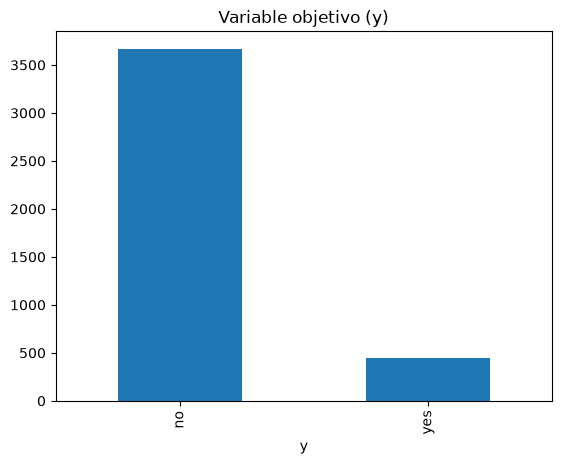

In [8]:
print(df["y"].value_counts())
print((df["y"] == "yes").mean())

df["y"].value_counts().plot(kind="bar")
plt.title("Variable objetivo (y)")
plt.show()

Vemos 3,668 clientes que dijeron que no y 451 que dijeron que sí, es decir, solo 10.9% contrató.

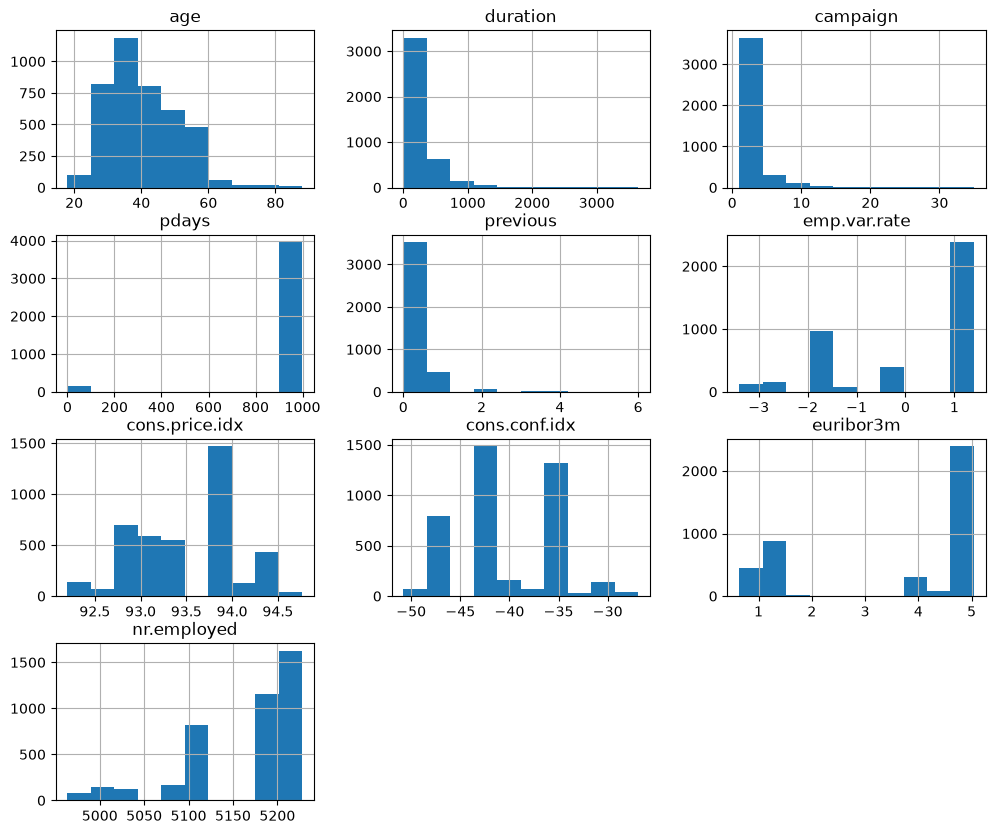

In [9]:
df.hist(figsize=(12, 10))
plt.show()

En los histogramas vemos `pdays` casi toda en 999, `previous` casi toda en 0 y a `campaign` y `duration` cargadas a la izquierda, con pocos valores muy altos.

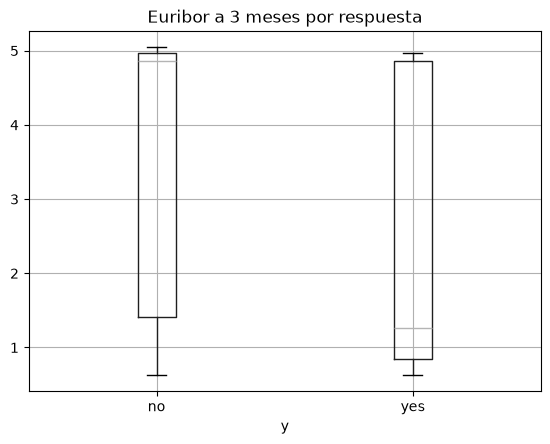

In [10]:
df.boxplot(column="euribor3m", by="y")
plt.suptitle("")
plt.title("Euribor a 3 meses por respuesta")
plt.show()

Vemos que la mediana de la Euribor es cercana a 4.9 en quienes no contrataron y cercana a 1.3 en quienes sí, por lo que se contrató más cuando las tasas estaban bajas.

In [11]:
print((df["pdays"] == 999).mean())
print(df["campaign"].median(), df["campaign"].max())

0.9611556202961884
2.0 35


Confirmamos que 96.1% de los clientes tiene `pdays` igual a 999 y que `campaign` tiene una mediana de 2 y un máximo de 35, así que las dos necesitan transformarse.

In [12]:
contrato = df["y"] == "yes"

print("Contactado antes:", contrato[df["pdays"] != 999].mean())
print("Nunca contactado:", contrato[df["pdays"] == 999].mean())
print("Campaña anterior exitosa:", contrato[df["poutcome"] == "success"].mean())
print("Euribor menor a 1.5:", contrato[df["euribor3m"] < 1.5].mean())
print("Euribor mayor a 4.5:", contrato[df["euribor3m"] > 4.5].mean())

Contactado antes: 0.625
Nunca contactado: 0.08865875221015408
Campaña anterior exitosa: 0.647887323943662
Euribor menor a 1.5: 0.2308276385725133
Euribor mayor a 4.5: 0.04891304347826087


Con Euribor debajo de 1.5 contrató 23.1%, frente a 4.9% con Euribor arriba de 4.5. El contacto previo pesa todavía más (62.5% frente a 8.9%) y sube a 64.8% cuando la campaña anterior fue exitosa, aunque son pocos clientes. Estas tasas son asociaciones y no prueban que la tasa de interés cause la contratación.

In [13]:
macro = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
df[macro].corr().round(2)

,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
emp.var.rate,1.00,0.76,0.20,0.97,0.90
cons.price.idx,0.76,1.00,0.05,0.66,0.47
cons.conf.idx,0.20,0.05,1.00,0.28,0.11
euribor3m,0.97,0.66,0.28,1.00,0.94
nr.employed,0.90,0.47,0.11,0.94,1.00


Vemos que `euribor3m` tiene una correlación de 0.97 con `emp.var.rate` y de 0.94 con `nr.employed`, así que las tres se mueven casi juntas. `cons.conf.idx` casi no se relaciona con ellas (0.28 como máximo con la Euribor).

## Limpieza y transformaciones

Quitamos `duration` y los duplicados, y juntamos `illiterate` con `basic.4y`.

In [14]:
df = df.drop(columns=["duration"])
df = df.drop_duplicates()
df["education"] = np.where(df["education"] == "illiterate", "basic.4y", df["education"])
print(df.shape)

(4100, 20)


Antes de limpiar no había duplicados, pero al quitar `duration` aparecen 19 y quedan 4,100 registros. Juntar `illiterate` con `basic.4y` no cambia el número de registros.

Creamos `contactado_antes` y `default_desconocido`, aplicamos el logaritmo a `campaign` y separamos `X` de `y`.

In [15]:
df["contactado_antes"] = (df["pdays"] != 999).astype(int)
df["default_desconocido"] = (df["default"] == "unknown").astype(int)
df = df.drop(columns=["pdays", "default"])

df["campaign"] = np.log1p(df["campaign"])

X = df.drop(columns=["y"])
y = (df["y"] == "yes").astype(int)

## Separación 70/30

Separamos antes de cualquier ajuste y dejamos el 30% de prueba para el final. K-Fold usa 10 grupos con `shuffle=True` y es el mismo para todos los modelos, por lo que todos se evalúan con las mismas particiones.

In [16]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Proporción de sí en train:", y_train.mean())
print("Proporción de sí en test:", y_test.mean())

Train: (2870, 19)  Test: (1230, 19)
Proporción de sí en train: 0.1073170731707317
Proporción de sí en test: 0.11544715447154472


In [17]:
kf = KFold(n_splits=10, shuffle=True, random_state=42)

Vemos 10.7% de "sí" en entrenamiento y 11.5% en prueba, una diferencia pequeña que viene de separar al azar. En prueba quedan 142 clientes que contrataron de 1,230.

# Modelo propuesto

Comparamos tres modelos, cada uno con optimización de hiperparámetros vía procesos gaussianos.

1. Regresión logística con regularización L2, donde optimizamos $C$.
2. Máquina de vectores de soporte con kernel RBF, donde optimizamos $C$ y $\gamma$.
3. Multi-layer perceptron con una capa oculta, donde optimizamos el número de neuronas y $\alpha$.

Por el desbalance usamos `class_weight="balanced"` en los dos primeros, para que la clase "sí" pese lo mismo que la clase "no". `MLPClassifier` no tiene ese parámetro, así que en prueba comparamos los modelos en varios umbrales y no solo en 0.5.

En los tres casos maximizamos el AUC promedio con K-Fold de 10 grupos sobre el conjunto de entrenamiento. El 30% restante se usa solo al final, para evaluar los modelos con datos que nunca vieron.

# Pipeline

<img src="img/pipeline.png" width="520">

Las variables numéricas pasan por `StandardScaler`, las categóricas por `OneHotEncoder` y `contactado_antes` y `default_desconocido` pasan sin cambios. Este preprocesamiento va dentro del pipeline para que en cada fold se ajuste solo con los datos de entrenamiento.

## Pipeline en código

In [18]:
numerical_cols = ["age", "campaign", "previous", "emp.var.rate", "cons.price.idx",
                  "cons.conf.idx", "euribor3m", "nr.employed"]
categorical_cols = ["job", "marital", "education", "housing", "loan", "contact",
                    "month", "day_of_week", "poutcome"]
boolean_cols = ["contactado_antes", "default_desconocido"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(), categorical_cols),
        ("bool", "passthrough", boolean_cols)
    ],
    remainder="drop"
)

## Optimización bayesiana (proceso gaussiano)

Cada función objetivo arma el pipeline con los hiperparámetros de `H`, que vienen como exponentes, y regresa el AUC promedio.

In [19]:
def objetivo_lr(H):
    C = 10**H[0]
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(C=C, class_weight="balanced", max_iter=1000))
    ])
    scores = cross_val_score(pipeline, X_train, y_train, cv=kf, scoring="roc_auc")
    return np.mean(scores)

def objetivo_svm(H):
    C = 10**H[0]
    gamma = 10**H[1]
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", SVC(kernel="rbf", C=C, gamma=gamma, class_weight="balanced", probability=True, random_state=42))
    ])
    scores = cross_val_score(pipeline, X_train, y_train, cv=kf, scoring="roc_auc")
    return np.mean(scores)

def objetivo_mlp(H):
    neuronas = int(2**H[0])
    alpha = 10**H[1]
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", MLPClassifier(hidden_layer_sizes=(neuronas,), alpha=alpha, max_iter=500, random_state=42))
    ])
    scores = cross_val_score(pipeline, X_train, y_train, cv=kf, scoring="roc_auc")
    return np.mean(scores)

kernel = 1.0*RBF(length_scale=1.0)

### Regresión logística con regularización

Evaluamos 5 valores de $C$ al azar y después dejamos que el proceso gaussiano elija los siguientes 15.

In [20]:
candidatos_lr = []
for c in np.linspace(-6, 2, 161):
    candidatos_lr.append([c])

np.random.seed(42)
c_ini = np.random.uniform(-6, 2, 5)

H_lr = []
auc_lr = []
for i in range(5):
    H_lr.append([c_ini[i]])
    auc_lr.append(objetivo_lr(H_lr[i]))

In [21]:
for i in range(15):
    gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10)
    gp.fit(np.array(H_lr), np.array(auc_lr) - np.mean(auc_lr))

    # Dejo solo las combinaciones que todavía no evalúo
    pendientes = []
    for h in candidatos_lr:
        if h not in H_lr:
            pendientes.append(h)
    H_new = np.array(pendientes)

    y_pred, desv = gp.predict(H_new, return_std=True)
    h_sig = H_new[np.argmax(y_pred + 2*desv)]
    H_lr.append([h_sig[0]])
    auc_lr.append(objetivo_lr(h_sig))

resultados_lr = pd.DataFrame(H_lr, columns=["Exponente de C"])
resultados_lr["C"] = 10**resultados_lr["Exponente de C"]
resultados_lr["AUC promedio"] = auc_lr
resultados_lr.round(4)

,Exponente de C,C,AUC promedio
0,-3.0037,0.0010,0.7654
1,1.6057,40.3380,0.7691
2,-0.1440,0.7177,0.7715
3,-1.2107,0.0616,0.7766
4,-4.7519,0.0000,0.7536
5,-1.7000,0.0200,0.7780
6,-1.6500,0.0224,0.7779
7,-1.7500,0.0178,0.7781
8,-2.3500,0.0045,0.7749
9,-6.0000,0.0000,0.7533


In [22]:
mejor_lr = H_lr[np.argmax(auc_lr)]
print("Mejor C:", 10**mejor_lr[0])
print("AUC:", max(auc_lr))

Mejor C: 0.01778279410038923
AUC: 0.7781359986421429


El mejor valor es $C$ = 0.018, con un AUC de 0.778. Con $C$ cerca de $10^{-6}$ el AUC baja a 0.753 porque el castigo casi anula los coeficientes, y con $C$ = 100 baja a 0.769, así que un castigo intermedio ayuda poco pero sí ayuda. El mejor punto queda lejos de los dos bordes del rango.

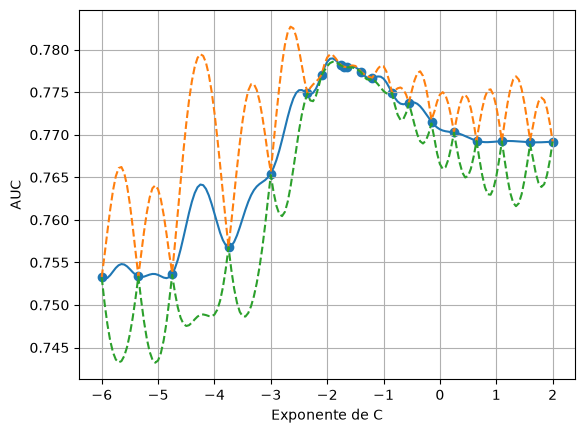

In [23]:
gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10)
gp.fit(np.array(H_lr), np.array(auc_lr) - np.mean(auc_lr))

X_new = np.array(candidatos_lr)
y_pred, desv = gp.predict(X_new, return_std=True)
y_pred = y_pred + np.mean(auc_lr)

plt.figure()
plt.plot(X_new, y_pred)
plt.plot(X_new, y_pred + 2*desv, linestyle='--')
plt.plot(X_new, y_pred - 2*desv, linestyle='--')
plt.scatter(np.array(H_lr), auc_lr)
plt.xlabel("Exponente de C")
plt.ylabel("AUC")
plt.grid()
plt.show()

En la gráfica vemos que la predicción sube hasta un exponente cercano a -1.75 y después baja poco a poco, y que el proceso gaussiano juntó sus evaluaciones alrededor de ese máximo. Las bandas son más anchas a la izquierda, donde evaluamos menos porque el AUC ahí es más bajo.

### SVM con kernel RBF

Armamos la malla de $C$ y $\gamma$ en exponentes y repetimos el mismo procedimiento.

In [24]:
candidatos_svm = []
for c in np.linspace(-2, 3, 26):
    for g in np.linspace(-6, 0, 31):
        candidatos_svm.append([c, g])

np.random.seed(42)
c_ini = np.random.uniform(-2, 3, 5)
g_ini = np.random.uniform(-6, 0, 5)

H_svm = []
auc_svm = []
for i in range(5):
    H_svm.append([c_ini[i], g_ini[i]])
    auc_svm.append(objetivo_svm(H_svm[i]))

c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\

In [25]:
for i in range(15):
    gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10)
    gp.fit(np.array(H_svm), np.array(auc_svm) - np.mean(auc_svm))

    pendientes = []
    for h in candidatos_svm:
        if h not in H_svm:
            pendientes.append(h)
    H_new = np.array(pendientes)

    y_pred, desv = gp.predict(H_new, return_std=True)
    h_sig = H_new[np.argmax(y_pred + 2*desv)]
    H_svm.append([h_sig[0], h_sig[1]])
    auc_svm.append(objetivo_svm(h_sig))

resultados_svm = pd.DataFrame(H_svm, columns=["Exponente de C", "Exponente de gamma"])
resultados_svm["C"] = 10**resultados_svm["Exponente de C"]
resultados_svm["gamma"] = 10**resultados_svm["Exponente de gamma"]
resultados_svm["AUC promedio"] = auc_svm
resultados_svm.round(6)

c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\

,Exponente de C,Exponente de gamma,C,gamma,AUC promedio
0,-0.127299,-5.064033,0.745934,0.000009,0.753227
1,2.753572,-5.651498,566.984951,0.000002,0.773014
2,1.659970,-0.802943,45.705631,0.157419,0.705352
3,0.993292,-2.393310,9.846739,0.004043,0.771363
4,-1.219907,-1.751565,0.060269,0.017719,0.772082
5,1.000000,-2.400000,10.000000,0.003981,0.771078
6,0.000000,-2.000000,1.000000,0.010000,0.774064
7,3.000000,-4.600000,1000.000000,0.000025,0.764409
8,0.000000,-3.000000,1.000000,0.001000,0.771191
9,-1.400000,-3.000000,0.039811,0.001000,0.753220


In [26]:
mejor_svm = H_svm[np.argmax(auc_svm)]
print("Mejor C:", 10**mejor_svm[0])
print("Mejor gamma:", 10**mejor_svm[1])
print("AUC:", max(auc_svm))

Mejor C: 0.25118864315095807
Mejor gamma: 0.039810717055349776
AUC: 0.7767648544749468


La mejor combinación es $C$ = 0.25 y $\gamma$ = 0.04, con un AUC de 0.777. Con $\gamma$ = 1 el AUC cae a 0.672, porque cada punto influye solo muy cerca y el modelo sobreajusta. Varias zonas muy distintas dan casi lo mismo, como $C$ = 567 con $\gamma$ = 0.000002 (0.773), lo que indica una frontera suave en ambos casos.

### Multi-layer perceptron

Las neuronas van como exponente de 2 y $\alpha$ como exponente de 10, para que el kernel trate a los dos con una escala parecida.

In [27]:
candidatos_mlp = []
for n in np.linspace(1, 7, 13):
    for a in np.linspace(-5, 2, 29):
        candidatos_mlp.append([n, a])

np.random.seed(42)
n_ini = np.random.uniform(1, 7, 5)
a_ini = np.random.uniform(-5, 2, 5)

H_mlp = []
auc_mlp = []
for i in range(5):
    H_mlp.append([n_ini[i], a_ini[i]])
    auc_mlp.append(objetivo_mlp(H_mlp[i]))

c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the opti

In [28]:
for i in range(15):
    gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10)
    gp.fit(np.array(H_mlp), np.array(auc_mlp) - np.mean(auc_mlp))

    pendientes = []
    for h in candidatos_mlp:
        if h not in H_mlp:
            pendientes.append(h)
    H_new = np.array(pendientes)

    y_pred, desv = gp.predict(H_new, return_std=True)
    h_sig = H_new[np.argmax(y_pred + 2*desv)]
    H_mlp.append([h_sig[0], h_sig[1]])
    auc_mlp.append(objetivo_mlp(h_sig))

resultados_mlp = pd.DataFrame(H_mlp, columns=["Exponente de neuronas", "Exponente de alpha"])
resultados_mlp["Neuronas"] = (2**resultados_mlp["Exponente de neuronas"]).astype(int)
resultados_mlp["alpha"] = 10**resultados_mlp["Exponente de alpha"]
resultados_mlp["AUC promedio"] = auc_mlp
resultados_mlp.round(5)

c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the opti

,Exponente de neuronas,Exponente de alpha,Neuronas,alpha,AUC promedio
0,3.24724,-3.90804,9,0.00012,0.73970
1,6.70429,-4.59341,104,0.00003,0.70263
2,5.39196,1.06323,41,11.56733,0.76432
3,4.59195,-0.79219,24,0.16136,0.74995
4,1.93611,-0.04349,3,0.90471,0.77308
5,1.00000,2.00000,2,100.00000,0.75148
6,1.00000,-2.25000,2,0.00562,0.73597
7,3.00000,1.00000,8,10.00000,0.76817
8,7.00000,2.00000,128,100.00000,0.75223
9,7.00000,-0.25000,128,0.56234,0.77026


In [29]:
mejor_mlp = H_mlp[np.argmax(auc_mlp)]
print("Mejores neuronas:", int(2**mejor_mlp[0]))
print("Mejor alpha:", 10**mejor_mlp[1])
print("AUC:", max(auc_mlp))

Mejores neuronas: 90
Mejor alpha: 3.1622776601683795
AUC: 0.7792020875067525


La mejor red tiene 90 neuronas y $\alpha$ = 3.16, con un AUC de 0.779, y las 20 evaluaciones son combinaciones distintas. La regularización importa mucho, porque con 16 neuronas el AUC pasa de 0.677 con $\alpha$ = 0.00001 a 0.779 con $\alpha$ = 1.78. Las redes con $\alpha$ chico llegan al límite de 500 iteraciones sin converger, pero el mejor resultado está en la zona de $\alpha$ alto, por lo que no cambiamos el límite.

## Optimización con Optuna (SVM con kernel RBF)

Repetimos la búsqueda de la SVM con Optuna para compararla con el proceso gaussiano. Usamos los mismos rangos, el mismo K-Fold y el mismo número de evaluaciones (20).

In [30]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    C = trial.suggest_float("C", 0.01, 1000, log=True)
    gamma = trial.suggest_float("gamma", 0.000001, 1, log=True)

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", SVC(kernel="rbf", C=C, gamma=gamma, class_weight="balanced", probability=True, random_state=42))
    ])
    scores = cross_val_score(pipeline, X_train, y_train, cv=kf, scoring="roc_auc")
    return np.mean(scores)

In [31]:
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))

%time study.optimize(objective, n_trials=20)
print(study.best_params)
print(study.best_value)

c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\

CPU times: total: 4min 57s
Wall time: 5min 24s
{'C': 26.596549826671303, 'gamma': 8.881520475754436e-05}
0.7738581755761145


In [32]:
intentos = study.trials_dataframe()
intentos = intentos[["number", "params_C", "params_gamma", "value"]]
intentos.columns = ["Intento", "C", "gamma", "AUC promedio"]
intentos.round(6)

,Intento,C,gamma,AUC promedio
0,0,0.745934,0.506158,0.704118
1,1,45.705631,0.003908,0.765671
2,2,0.060269,0.000009,0.753227
3,3,0.019517,0.157419,0.762940
4,4,10.129198,0.017719,0.743741
5,5,0.012674,0.659871,0.709941
6,6,145.282466,0.000019,0.773657
7,7,0.081119,0.000013,0.753215
8,8,0.332056,0.001408,0.770475
9,9,1.444525,0.000056,0.757057


In [33]:
comparacion = pd.DataFrame([
    ["Proceso gaussiano", 10**mejor_svm[0], 10**mejor_svm[1], max(auc_svm)],
    ["Optuna", study.best_params["C"], study.best_params["gamma"], study.best_value]
], columns=["Método", "C", "gamma", "AUC promedio"])
comparacion

,Método,C,gamma,AUC promedio
0,Proceso gaussiano,0.251189,0.039811,0.776765
1,Optuna,26.596550,0.000089,0.773858


Optuna llega a un AUC de 0.774 con $C$ = 26.6 y $\gamma$ = 0.00009, frente a 0.777 de nuestro proceso gaussiano con $C$ = 0.25 y $\gamma$ = 0.04. La diferencia de 0.003 es menor que la desviación entre folds, así que con 20 evaluaciones los dos métodos quedan parejos, aunque en zonas distintas de los hiperparámetros.

## Comparación de modelos (K-Fold)

In [34]:
modelos = [
    ("Regresión logística", LogisticRegression(C=10**mejor_lr[0], class_weight="balanced", max_iter=1000)),
    ("SVM RBF", SVC(kernel="rbf", C=10**mejor_svm[0], gamma=10**mejor_svm[1], class_weight="balanced",
                    probability=True, random_state=42)),
    ("MLP", MLPClassifier(hidden_layer_sizes=(int(2**mejor_mlp[0]),), alpha=10**mejor_mlp[1], max_iter=500, random_state=42))
]

resultados = []

for nombre, modelo in modelos:
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", modelo)
    ])
    scores = cross_val_score(pipeline, X_train, y_train, cv=kf, scoring="roc_auc")
    resultados.append([nombre, np.mean(scores), np.std(scores)])

tabla = pd.DataFrame(resultados, columns=["Modelo", "AUC promedio", "Desviación estándar"])
tabla.round(4)

c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\

,Modelo,AUC promedio,Desviación estándar
0,Regresión logística,0.7781,0.0392
1,SVM RBF,0.7768,0.0374
2,MLP,0.7792,0.0394


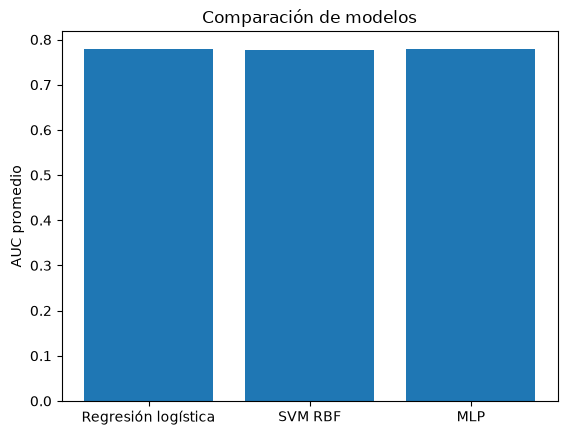

In [35]:
plt.figure()
plt.bar(tabla["Modelo"], tabla["AUC promedio"])
plt.ylabel("AUC promedio")
plt.title("Comparación de modelos")
plt.show()

Vemos un empate entre los tres modelos, con AUC promedio de 0.778 en la regresión logística, 0.777 en la SVM y 0.779 en el MLP. La mayor diferencia es de 0.002 y la desviación estándar entre folds es cercana a 0.04, por lo que K-Fold no permite decir que uno sea mejor. Estos promedios son los mismos con los que elegimos los hiperparámetros, así que pueden salir algo optimistas.

## Evaluación en prueba

Ajustamos cada modelo con todo el conjunto de entrenamiento y calculamos las métricas para cinco umbrales. El mismo umbral no significa lo mismo en los tres modelos, porque `class_weight="balanced"` sube las probabilidades de la regresión logística, así que los comparamos por los clientes que marcan y no por el umbral.

In [36]:
umbrales = [0.7, 0.5, 0.3, 0.2, 0.1]
metricas = []
probabilidades = []

for nombre, modelo in modelos:
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", modelo)
    ])
    pipeline.fit(X_train, y_train)
    prob = pipeline.predict_proba(X_test)[:, 1]
    probabilidades.append([nombre, prob])
    auc = roc_auc_score(y_test, prob)

    for t in umbrales:
        y_pred = (prob >= t).astype(int)
        tp = ((y_pred == 1) & (y_test == 1)).sum()
        tn = ((y_pred == 0) & (y_test == 0)).sum()
        fp = ((y_pred == 1) & (y_test == 0)).sum()
        fn = ((y_pred == 0) & (y_test == 1)).sum()

        # Con un umbral alto un modelo puede no marcar a nadie y la precisión no existe
        if tp + fp > 0:
            acc = (tp + tn) / (tp + tn + fp + fn)
            rec = tp / (tp + fn)
            pre = tp / (tp + fp)
            esp = tn / (tn + fp)
            f1 = 2 * pre * rec / (pre + rec)
            metricas.append([nombre, t, rec, pre, esp, acc, f1, tp + fp, auc])

tabla_test = pd.DataFrame(metricas, columns=["Modelo", "Umbral", "Recall", "Precisión", "Especificidad",
                                             "Accuracy", "F1", "Clientes marcados", "AUC"])
tabla_test.round(3)

c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Modelo,Umbral,Recall,Precisión,Especificidad,Accuracy,F1,Clientes marcados,AUC
0,Regresión logística,0.7,0.423,0.484,0.941,0.881,0.451,124,0.765
1,Regresión logística,0.5,0.585,0.358,0.863,0.831,0.444,232,0.765
2,Regresión logística,0.3,0.838,0.160,0.424,0.472,0.268,746,0.765
3,Regresión logística,0.2,0.965,0.120,0.080,0.182,0.214,1138,0.765
4,Regresión logística,0.1,1.000,0.115,0.000,0.115,0.207,1230,0.765
5,SVM RBF,0.5,0.007,1.000,1.000,0.885,0.014,1,0.760
6,SVM RBF,0.3,0.472,0.500,0.938,0.885,0.486,134,0.760
7,SVM RBF,0.2,0.521,0.423,0.907,0.863,0.467,175,0.760
8,SVM RBF,0.1,0.620,0.336,0.840,0.815,0.436,262,0.760
9,MLP,0.7,0.028,0.800,0.999,0.887,0.054,5,0.760


El AUC de prueba es de 0.765 en la regresión logística y de 0.760 en la SVM y el MLP. Baja un poco respecto a K-Fold, como se espera, y el empate se mantiene. También vemos por qué el accuracy engaña, porque con umbral de 0.5 el MLP tiene 0.893 pero solo detecta 12.7% de los que contratan.

Para comparar en condiciones parecidas buscamos el umbral que marca una cantidad similar de clientes. Con recall cerca de 60%, la regresión logística marca 232 clientes (umbral de 0.5, precisión de 35.8%), la SVM marca 262 (umbral de 0.1, precisión de 33.6%) y el MLP marca 303 (umbral de 0.1, precisión de 30.0%). Estos umbrales los elegimos viendo la tabla de prueba, así que sirven para describir a los modelos y no como un resultado independiente.

Regresión logística con umbral de 0.5
              precision    recall  f1-score   support

          No       0.94      0.86      0.90      1088
          Sí       0.36      0.58      0.44       142

    accuracy                           0.83      1230
   macro avg       0.65      0.72      0.67      1230
weighted avg       0.87      0.83      0.85      1230



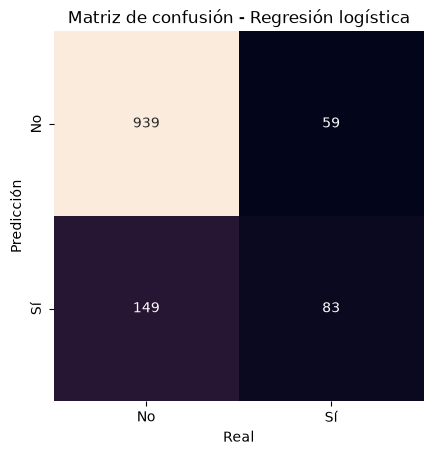

SVM RBF con umbral de 0.1
              precision    recall  f1-score   support

          No       0.94      0.84      0.89      1088
          Sí       0.34      0.62      0.44       142

    accuracy                           0.81      1230
   macro avg       0.64      0.73      0.66      1230
weighted avg       0.87      0.81      0.84      1230



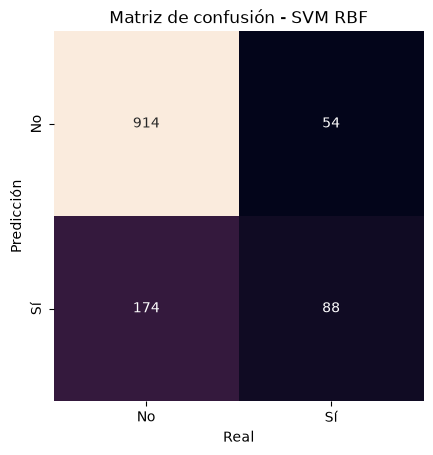

MLP con umbral de 0.1
              precision    recall  f1-score   support

          No       0.94      0.81      0.87      1088
          Sí       0.30      0.64      0.41       142

    accuracy                           0.79      1230
   macro avg       0.62      0.72      0.64      1230
weighted avg       0.87      0.79      0.82      1230



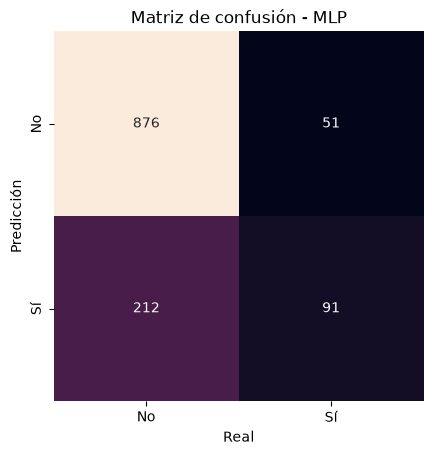

In [37]:
umbrales_reporte = [0.5, 0.1, 0.1]

for i in range(3):
    nombre = probabilidades[i][0]
    prob = probabilidades[i][1]
    y_pred = (prob >= umbrales_reporte[i]).astype(int)

    print(nombre, "con umbral de", umbrales_reporte[i])
    print(classification_report(y_test, y_pred, target_names=["No", "Sí"]))

    mat = confusion_matrix(y_test, y_pred)
    plt.figure()
    sns.heatmap(mat.T, square=True, annot=True, fmt="d", cbar=False,
                xticklabels=["No", "Sí"], yticklabels=["No", "Sí"])
    plt.xlabel("Real")
    plt.ylabel("Predicción")
    plt.title("Matriz de confusión - " + nombre)
    plt.show()

En las matrices vemos que la regresión logística encuentra 83 de los 142 clientes que contratan y se le escapan 59. La SVM encuentra 5 más y el MLP 8 más, pero a cambio marcan 30 y 71 clientes más que la regresión logística.

# Conclusión

Sí es posible predecir mejor que el azar quién contratará un depósito a plazo con la información disponible antes de la llamada, aunque de forma limitada. Los tres modelos llegan a un AUC cercano a 0.78 en K-Fold y a 0.76 en prueba, frente al 0.5 de adivinar.

Respecto a los objetivos específicos, el análisis del dataset nos llevó a quitar `duration` por fuga de información y a tratar `"unknown"` como una categoría más, y las transformaciones y el pipeline dejaron 4,100 registros listos para los tres modelos sin ajustar el escalamiento con datos de validación. La optimización bayesiana encontró hiperparámetros dentro de los rangos, sin tocar sus bordes, con 20 evaluaciones por modelo, y Optuna llegó a un AUC similar en la SVM (0.774 frente a 0.777).

En la comparación, los tres modelos empatan, con una diferencia máxima de 0.002 frente a una desviación de 0.04. Nos quedamos con la regresión logística porque tiene el AUC de prueba más alto (0.765) por una diferencia pequeña, marca menos clientes para detectar una proporción parecida de los que contratan y es la más sencilla de ajustar. La SVM y el MLP no compensan su mayor costo, lo que indica que las relaciones no lineales aportan poco en estos datos.

Lo que esperábamos se cumple en parte. El contacto previo y la Euribor sí se asocian con la contratación, y la regularización ayudó, sobre todo en el MLP, aunque en la regresión logística el AUC solo pasa de 0.769 a 0.778.

En la práctica, si el banco llama solo a los 232 clientes que marca el modelo (19% de la muestra de prueba), alcanza 58.5% de los que contratan y su tasa de éxito pasa de 11.5% a 35.8%. La principal limitación es que separamos los datos al azar, mientras que `month` y las variables macroeconómicas permiten reconocer el periodo, de modo que el desempeño en una campaña futura, con otra situación económica, podría ser menor.

# Referencias

Abe, S. (2010). *Support vector machines for pattern classification* (2nd ed.). Springer.

Akiba, T., Sano, S., Yanase, T., Ohta, T., & Koyama, M. (2019). Optuna: A next-generation hyperparameter optimization framework. En *Proceedings of the 25th ACM SIGKDD International Conference on Knowledge Discovery & Data Mining* (pp. 2623–2631). https://doi.org/10.1145/3292500.3330701

Bradley, A. P. (1997). The use of the area under the ROC curve in the evaluation of machine learning algorithms. *Pattern Recognition, 30*(7), 1145–1159. https://doi.org/10.1016/S0031-3203(96)00142-2

James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). *An introduction to statistical learning with applications in Python*. Springer.

Moro, S., Cortez, P., & Rita, P. (2014). A data-driven approach to predict the success of bank telemarketing. *Decision Support Systems, 62*, 22–31. https://doi.org/10.1016/j.dss.2014.03.001

Moro, S., Rita, P., & Cortez, P. (2014). *Bank Marketing* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5K306

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

Rasmussen, C. E., & Williams, C. K. I. (2006). *Gaussian processes for machine learning*. MIT Press.